In [16]:
import pandas as pd
import numpy as np
import matplotlib as plt

In [35]:
df = pd.read_csv(r"c:\Users\GLXTCH\Downloads\datasettttt.csv")
df

,Customer_ID,Age,Gender,Income,Education_Level,Marital_Status,Years_with_Company,Satisfaction_Score,Purchased
0,1,56.0,Other,108652.0,High School,Widowed,26.0,6.687898,No
1,2,69.0,Other,132755.0,PhD,Single,25.0,1.858344,No
2,3,NaN,Other,76985.0,NaN,Widowed,29.0,1.933107,Yes
3,4,32.0,Male,70069.0,NaN,Widowed,24.0,1.437919,Yes
4,5,60.0,Other,NaN,NaN,NaN,11.0,6.229136,No
...,...,...,...,...,...,...,...,...,...
995,996,60.0,Male,27099.0,High School,Divorced,1.0,3.907897,No
996,997,NaN,Male,138614.0,Master,Widowed,29.0,9.889746,No
997,998,62.0,Male,45431.0,PhD,Widowed,16.0,3.931163,Yes
998,999,35.0,Female,76492.0,NaN,Widowed,8.0,4.547224,Yes


In [29]:
df.shape

(1000, 9)

In [30]:
df.describe()

,Customer_ID,Age,Income,Years_with_Company,Satisfaction_Score
count,1000.000000,850.000000,850.000000,1000.000,850.000000
mean,500.500000,43.721176,86691.327059,14.940,5.495345
std,288.819436,14.948160,37787.622723,8.753,2.601818
min,1.000000,18.000000,20163.000000,0.000,1.001679
25%,250.750000,31.000000,52417.250000,7.000,3.245225
50%,500.500000,43.000000,86042.500000,16.000,5.552657
75%,750.250000,56.000000,119948.000000,22.250,7.822599
max,1000.000000,69.000000,149992.000000,29.000,9.978605


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         1000 non-null   int64  
 1   Age                 850 non-null    float64
 2   Gender              1000 non-null   object 
 3   Income              850 non-null    float64
 4   Education_Level     850 non-null    object 
 5   Marital_Status      850 non-null    object 
 6   Years_with_Company  1000 non-null   float64
 7   Satisfaction_Score  850 non-null    float64
 8   Purchased           1000 non-null   object 
dtypes: float64(4), int64(1), object(4)
memory usage: 70.4+ KB


In [31]:
df.isnull().sum()

Customer_ID             0
Age                   150
Gender                  0
Income                150
Education_Level       150
Marital_Status        150
Years_with_Company      0
Satisfaction_Score    150
Purchased               0
dtype: int64

## Checking Outliers

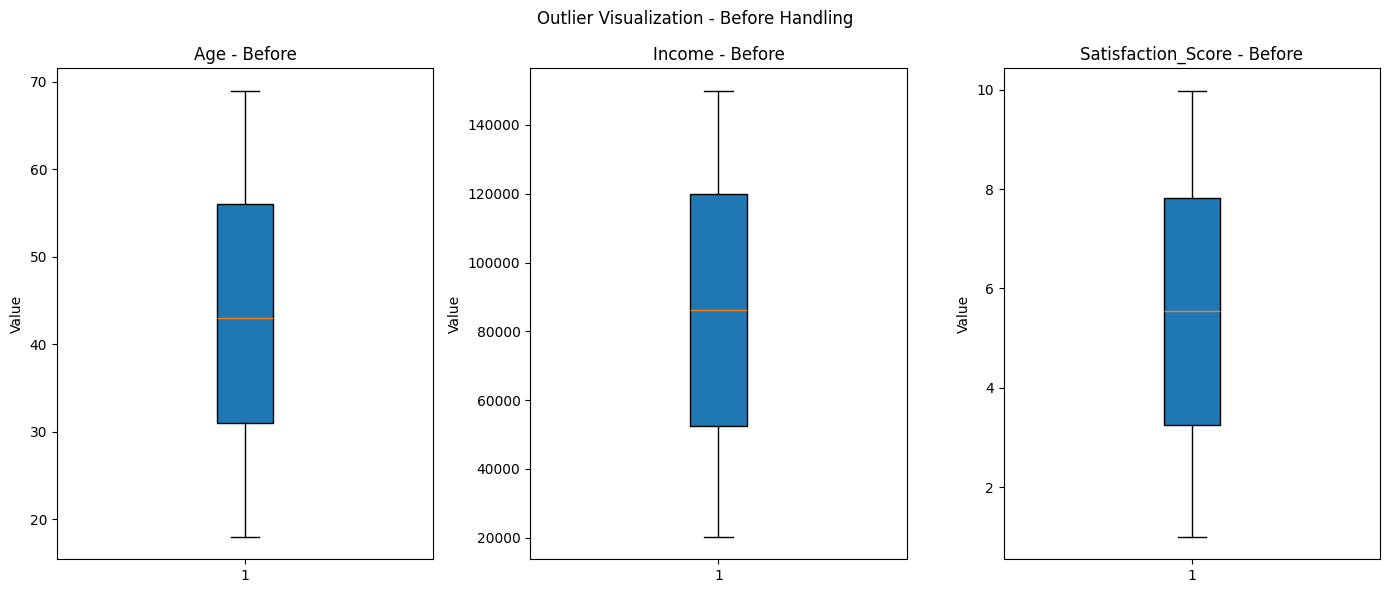

In [40]:
# --- BEFORE: Original Boxplots with outliers ---

plt.figure(figsize=(14,6))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    plt.boxplot(df[col].dropna(), patch_artist=True,
                flierprops=dict(marker='o', color='red', markersize=5))
    plt.title(f'{col} - Before')
    plt.ylabel('Value')
plt.suptitle('Outlier Visualization - Before Handling')
plt.tight_layout()
plt.show()


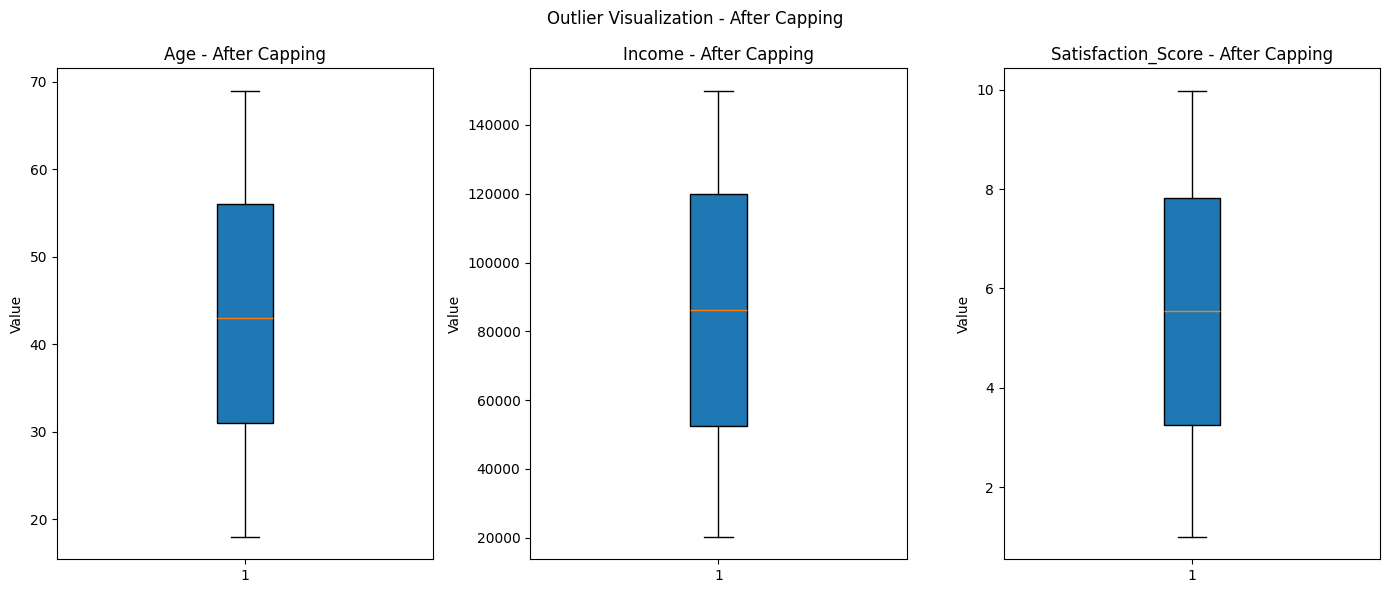

In [37]:
df_capped = df.copy()
for col in num_cols:
    Q1 = df_capped[col].quantile(0.25)
    Q3 = df_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Cap outliers
    df_capped[col] = df_capped[col].apply(lambda x: lower_bound if x < lower_bound 
                                          else (upper_bound if x > upper_bound else x))

# --- AFTER: Boxplots with capped outliers ---
plt.figure(figsize=(14,6))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    plt.boxplot(df_capped[col].dropna(), patch_artist=True,
                flierprops=dict(marker='o', color='red', markersize=5))
    plt.title(f'{col} - After Capping')
    plt.ylabel('Value')
plt.suptitle('Outlier Visualization - After Capping')
plt.tight_layout()
plt.show()

## Handling missing values Categorical Columns

In [22]:
df['Education_Level'] = df['Education_Level'].fillna(df['Education_Level'].mode().iloc[0])
df['Marital_Status'] = df['Marital_Status'].fillna(df['Marital_Status'].mode().iloc[0])
df['Purchased'] = df['Purchased'].fillna(df['Purchased'].mode().iloc[0])


In [23]:
df.isnull().sum()

Customer_ID             0
Age                   150
Gender                  0
Income                150
Education_Level         0
Marital_Status          0
Years_with_Company      0
Satisfaction_Score    150
Purchased               0
dtype: int64

## Handling numerical column

In [24]:
df['Income'] = df['Income'].fillna(df['Income'].median())
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Satisfaction_Score'] = df['Satisfaction_Score'].fillna(df['Satisfaction_Score'].median())

In [26]:
df.isnull().sum()

Customer_ID           0
Age                   0
Gender                0
Income                0
Education_Level       0
Marital_Status        0
Years_with_Company    0
Satisfaction_Score    0
Purchased             0
dtype: int64